Блок 1: Підготовка даних та імпорт бібліотек

Спочатку нам потрібні бібліотеки для роботи з масивами (NumPy), візуалізації (Matplotlib) та датасет. Ми використаємо fetch_openml для зручного завантаження Fashion-MNIST. Далі дані нормалізуються (ділимо на 255), щоб значення пікселів були в діапазоні [0, 1] — це важливо для стабільності градієнтного спуску.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import ssl

# Вимикаємо перевірку SSL-сертифікатів для поточного сеансу
ssl._create_default_https_context = ssl._create_unverified_context
# Фіксуємо seed для відтворюваності результатів
np.random.seed(42)

print("Завантаження датасету Fashion-MNIST...")
# Завантажуємо дані. Це може зайняти хвилину.
X, y = fetch_openml('Fashion-MNIST', version=1, return_X_y=True, as_frame=False, parser='auto')
y = y.astype(int)

# Нормалізація значень пікселів до діапазону [0, 1]
X = X / 255.0

# Розбиваємо дані на тренувальну, валідаційну та тестову вибірки
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=10000, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=10000, random_state=42)

# Для швидкості виконання лабораторної беремо підмножину даних (як дозволено в інструкції)
# Якщо у вас потужний комп'ютер, можете прибрати ці рядки
subset_size = 10000
X_train = X_train[:subset_size]
y_train = y_train[:subset_size]
X_val = X_val[:2000]
y_val = y_val[:2000]

print(f"Розмірність тренувальної вибірки: {X_train.shape}")
print(f"Розмірність валідаційної вибірки: {X_val.shape}")

Завантаження датасету Fashion-MNIST...
Розмірність тренувальної вибірки: (10000, 784)
Розмірність валідаційної вибірки: (2000, 784)


Блок 2: Реалізація нейронної мережі (MLP) з нуля:

Ініціалізація He: Ваги ініціалізуються випадковими значеннями з нормального розподілу з дисперсією 2/n_{in}. Це запобігає затуханню градієнтів при використанні ReLU.   
Forward pass: Рахуємо Z = AW + b та активацію A = ReLU(Z). На виході використовуємо Softmax для отримання ймовірностей.   
Backward pass: Починаємо з помилки на виході (Cross-Entropy + Softmax дає зручний градієнт P - Y). Рухаємось назад, домножуючи на похідну ReLU.   
Регуляризація: Вбудовано L1, L2, Dropout, Weight Clipping та Gradient Clipping.

In [2]:
class CustomMLP:
    def __init__(self, layer_sizes, reg_l1=0.0, reg_l2=0.0, dropout_p=0.0, weight_clip=None, grad_clip=None):
        self.num_layers = len(layer_sizes) - 1
        self.weights = []
        self.biases = []
        
        self.reg_l1 = reg_l1
        self.reg_l2 = reg_l2
        self.dropout_p = dropout_p
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        
        # Ініціалізація He для шарів з ReLU
        for i in range(self.num_layers):
            n_in = layer_sizes[i]
            n_out = layer_sizes[i+1]
            W = np.random.randn(n_in, n_out) * np.sqrt(2.0 / n_in)
            b = np.zeros((1, n_out))
            self.weights.append(W)
            self.biases.append(b)

    def forward(self, X, is_training=True):
        self.activations = [X]
        self.z_values = []
        self.dropout_masks = []
        A = X
        
        # Приховані шари (ReLU)
        for i, (W, b) in enumerate(zip(self.weights[:-1], self.biases[:-1])):
            Z = A @ W + b
            A = np.maximum(0, Z) # ReLU
            
            # Inverted Dropout (випадкове вимикання нейронів)
            if self.dropout_p > 0 and is_training:
                mask = np.random.binomial(1, 1 - self.dropout_p, size=A.shape)
                A = (A * mask) / (1 - self.dropout_p)
                self.dropout_masks.append(mask)
            else:
                self.dropout_masks.append(None)
                
            self.z_values.append(Z)
            self.activations.append(A)
            
        # Вихідний шар (Softmax)
        Z = A @ self.weights[-1] + self.biases[-1]
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True) # Для стабільності експоненти
        exp_Z = np.exp(Z_shifted)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
        
        self.z_values.append(Z)
        self.activations.append(P)
        return P

    def backward(self, y_true):
        n = y_true.shape[0]
        grads_W = [None] * len(self.weights)
        grads_b = [None] * len(self.biases)
        
        # Градієнт останнього шару (Softmax + Categorical Cross-Entropy)
        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1
        delta /= n 
        
        # Зворотне поширення
        for l in reversed(range(len(self.weights))):
            A_prev = self.activations[l]
            
            grads_W[l] = A_prev.T @ delta
            grads_b[l] = np.sum(delta, axis=0, keepdims=True)
            
            # Додаємо штрафи L2 та L1 до градієнтів ваг
            if self.reg_l2 > 0:
                grads_W[l] += self.reg_l2 * self.weights[l]
            if self.reg_l1 > 0:
                grads_W[l] += self.reg_l1 * np.sign(self.weights[l])
                
            if l > 0: # Рахуємо дельту для наступного кроку (якщо це не вхідний шар)
                delta = delta @ self.weights[l].T
                
                # Враховуємо Dropout маску
                if self.dropout_p > 0 and self.dropout_masks[l-1] is not None:
                    delta = (delta * self.dropout_masks[l-1]) / (1 - self.dropout_p)
                    
                # Похідна ReLU (множимо на 1, де Z > 0, і на 0 інакше)
                delta *= (self.z_values[l-1] > 0)
                
        # Gradient clipping
        if self.grad_clip is not None:
            total_norm = np.sqrt(sum(np.sum(g**2) for g in grads_W))
            if total_norm > 0:
                clip_coef = min(1.0, self.grad_clip / total_norm)
                for i in range(len(grads_W)):
                    grads_W[i] *= clip_coef
                    
        return grads_W, grads_b

    def update_params(self, grads_W, grads_b, lr):
        # SGD Оновлення параметрів
        for i in range(self.num_layers):
            self.weights[i] -= lr * grads_W[i]
            self.biases[i] -= lr * grads_b[i]
            
            # Weight clipping
            if self.weight_clip is not None:
                self.weights[i] = np.clip(self.weights[i], -self.weight_clip, self.weight_clip)

    def save_weights(self, path):
        data = {f'W_{i}': W for i, W in enumerate(self.weights)}
        data.update({f'b_{i}': b for i, b in enumerate(self.biases)})
        np.savez(path, **data)

    def load_weights(self, path):
        data = np.load(path)
        self.weights = [data[f'W_{i}'] for i in range(self.num_layers)]
        self.biases = [data[f'b_{i}'] for i in range(self.num_layers)]
        
    def get_dead_neurons_stats(self, X):
        # Знаходимо мертві нейрони (Z <= 0 для всіх об'єктів вибірки)
        self.forward(X, is_training=False)
        stats = []
        for l, Z in enumerate(self.z_values[:-1]):
            max_z = np.max(Z, axis=0) # Максимум по батчу
            n_dead = np.sum(max_z <= 0)
            n_total = Z.shape[1]
            stats.append({
                'layer': l+1,
                'dead': n_dead,
                'total': n_total,
                'percent': (n_dead / n_total) * 100
            })
        return stats
        
    def get_sparsity(self):
        # Відсоток ваг, близьких до нуля (< 0.01)
        total_w = sum(W.size for W in self.weights)
        small_w = sum(np.sum(np.abs(W) < 0.01) for W in self.weights)
        return (small_w / total_w) * 100

Блок 3: Допоміжні функції (Втрати, цикл навчання, чисельні градієнти)

Тренування відбувається епохами з розбиттям на міні-батчі. Також тут є важливий етап - check_gradients, який бере одну випадкову вагу, трохи її змінює (на epsilon) і перевіряє, чи аналітична формула backward дає такий самий результат, як і математичне наближення похідної.

In [3]:
def compute_loss(P, y_true):
    n = y_true.shape[0]
    log_likelihood = -np.log(P[np.arange(n), y_true] + 1e-12)
    return np.mean(log_likelihood)

def train_model(model, X_train, y_train, X_val, y_val, epochs=20, batch_size=128, lr=0.1, verbose=True):
    n_samples = X_train.shape[0]
    for epoch in range(epochs):
        # Перемішування
        indices = np.random.permutation(n_samples)
        X_train_sh = X_train[indices]
        y_train_sh = y_train[indices]
        
        for i in range(0, n_samples, batch_size):
            X_batch = X_train_sh[i:i+batch_size]
            y_batch = y_train_sh[i:i+batch_size]
            
            model.forward(X_batch, is_training=True)
            grads_W, grads_b = model.backward(y_batch)
            model.update_params(grads_W, grads_b, lr)
            
        if verbose and ((epoch+1) % 10 == 0 or epoch == 0):
            P_val = model.forward(X_val, is_training=False)
            val_loss = compute_loss(P_val, y_val)
            val_acc = accuracy_score(y_val, np.argmax(P_val, axis=1))
            print(f"Епоха {epoch+1:02d}/{epochs} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

def check_gradients(model, X, y, epsilon=1e-5):
    print(">>> Перевірка градієнтів...")
    model.forward(X, is_training=False)
    analytic_grads, _ = model.backward(y)
    
    # Вибираємо шар 1 та випадкову вагу
    l, i, j = 1, 0, 0 
    original_w = model.weights[l][i, j]
    
    # f(x + eps)
    model.weights[l][i, j] = original_w + epsilon
    loss_plus = compute_loss(model.forward(X, is_training=False), y)
    
    # f(x - eps)
    model.weights[l][i, j] = original_w - epsilon
    loss_minus = compute_loss(model.forward(X, is_training=False), y)
    
    model.weights[l][i, j] = original_w # Відновлюємо вагу
    
    numeric_grad = (loss_plus - loss_minus) / (2 * epsilon)
    analytic_grad = analytic_grads[l][i, j]
    
    rel_error = abs(analytic_grad - numeric_grad) / max(1e-8, abs(analytic_grad) + abs(numeric_grad))
    print(f"Чисельний: {numeric_grad:.8f}, Аналітичний: {analytic_grad:.8f}, Відносна похибка: {rel_error:.8e}")
    if rel_error < 1e-4:
        print(">>> Перевірка градієнтів успішна!\n")

def test_saving():
    print(">>> Перевірка збереження/відновлення ваг...")
    m1 = CustomMLP([784, 128, 10])
    m1.save_weights('test.npz')
    
    m2 = CustomMLP([784, 128, 10])
    m2.load_weights('test.npz')
    
    diff = np.max(np.abs(m1.weights[0] - m2.weights[0]))
    if diff == 0.0:
        print(">>> Збереження працює ідеально!\n")

# Запускаємо тести з блоку 1
test_model = CustomMLP([784, 128, 64, 10])
check_gradients(test_model, X_train[:5], y_train[:5])
test_saving()

>>> Перевірка градієнтів...
Чисельний: 0.00578223, Аналітичний: 0.00578223, Відносна похибка: 6.38612254e-10
>>> Перевірка градієнтів успішна!

>>> Перевірка збереження/відновлення ваг...
>>> Збереження працює ідеально!



Блок 4: Проведення експериментів з регуляризації

Тепер ми перевіримо базову модель та 7 різних методів регуляризації. Архітектура всюди однакова: 784 -> 256 -> 128 -> 64 -> 10. Ми навчимо кожну і збережемо результати.

In [4]:
layer_sizes = [784, 256, 128, 64, 10]
epochs = 30
batch_size = 128
lr = 0.1

results = {}
models_dict = {}

# Конфігурації експериментів
experiments = {
    'Без регуляризації': {},
    'L2 (lambda=0.001)': {'reg_l2': 0.001},
    'L1 (lambda=0.0001)': {'reg_l1': 0.0001},
    'Dropout (p=0.1)': {'dropout_p': 0.1},
    'Dropout (p=0.3)': {'dropout_p': 0.3},
    'Dropout (p=0.5)': {'dropout_p': 0.5},
    'Weight Clip (c=0.1)': {'weight_clip': 0.1},
    'Grad Clip (c=1.0)': {'grad_clip': 1.0},
    'L2 + Dropout (0.001, 0.2)': {'reg_l2': 0.001, 'dropout_p': 0.2}
}

for name, params in experiments.items():
    print(f"Початок навчання: {name}...")
    model = CustomMLP(layer_sizes, **params)
    train_model(model, X_train, y_train, X_val, y_val, epochs=epochs, batch_size=batch_size, lr=lr, verbose=False)
    
    # Розрахунок метрик
    P_val = model.forward(X_val, is_training=False)
    val_acc = accuracy_score(y_val, np.argmax(P_val, axis=1))
    val_loss = compute_loss(P_val, y_val)
    
    dead_stats = model.get_dead_neurons_stats(X_train)
    avg_dead = np.mean([s['percent'] for s in dead_stats])
    sparsity = model.get_sparsity()
    
    results[name] = {
        'val_acc': val_acc,
        'val_loss': val_loss,
        'dead_percent': avg_dead,
        'sparsity': sparsity,
        'dead_details': dead_stats
    }
    models_dict[name] = model
    print(f"Завершено. Точність (Val): {val_acc:.4f}, Мертвих нейронів: {avg_dead:.1f}%, Sparsity: {sparsity:.1f}%")

Початок навчання: Без регуляризації...
Завершено. Точність (Val): 0.8055, Мертвих нейронів: 0.0%, Sparsity: 13.6%
Початок навчання: L2 (lambda=0.001)...
Завершено. Точність (Val): 0.8375, Мертвих нейронів: 0.0%, Sparsity: 17.1%
Початок навчання: L1 (lambda=0.0001)...
Завершено. Точність (Val): 0.8355, Мертвих нейронів: 0.5%, Sparsity: 42.8%
Початок навчання: Dropout (p=0.1)...
Завершено. Точність (Val): 0.8675, Мертвих нейронів: 0.0%, Sparsity: 13.8%
Початок навчання: Dropout (p=0.3)...
Завершено. Точність (Val): 0.8125, Мертвих нейронів: 0.0%, Sparsity: 13.8%
Початок навчання: Dropout (p=0.5)...
Завершено. Точність (Val): 0.7970, Мертвих нейронів: 0.1%, Sparsity: 13.9%
Початок навчання: Weight Clip (c=0.1)...
Завершено. Точність (Val): 0.7070, Мертвих нейронів: 0.8%, Sparsity: 13.7%
Початок навчання: Grad Clip (c=1.0)...
Завершено. Точність (Val): 0.8475, Мертвих нейронів: 0.5%, Sparsity: 14.1%
Початок навчання: L2 + Dropout (0.001, 0.2)...
Завершено. Точність (Val): 0.7695, Мертвих н

Блок 5: Візуалізація та Аналіз (Таблиця, Гістограми, Scatter plot)

Виводимо таблицю для порівняння. Будуємо гістограми ваг. Залежність "мертві нейрони vs точність" допоможе побачити, чи дійсно мертві нейрони псують якість моделі.


--- Порівняльна таблиця результатів ---
                       Метод Dead neurons, % Sparsity, % Val. accuracy Val. loss
0          Без регуляризації            0.00       13.59        0.8055    0.5884
1          L2 (lambda=0.001)            0.00       17.09        0.8375    0.4846
2         L1 (lambda=0.0001)            0.52       42.75        0.8355    0.4515
3            Dropout (p=0.1)            0.00       13.77        0.8675    0.3851
4            Dropout (p=0.3)            0.00       13.76        0.8125    0.4768
5            Dropout (p=0.5)            0.13       13.94        0.7970    0.5606
6        Weight Clip (c=0.1)            0.78       13.69        0.7070    0.7419
7          Grad Clip (c=1.0)            0.52       14.11        0.8475    0.4237
8  L2 + Dropout (0.001, 0.2)            1.04       17.08        0.7695    0.6604


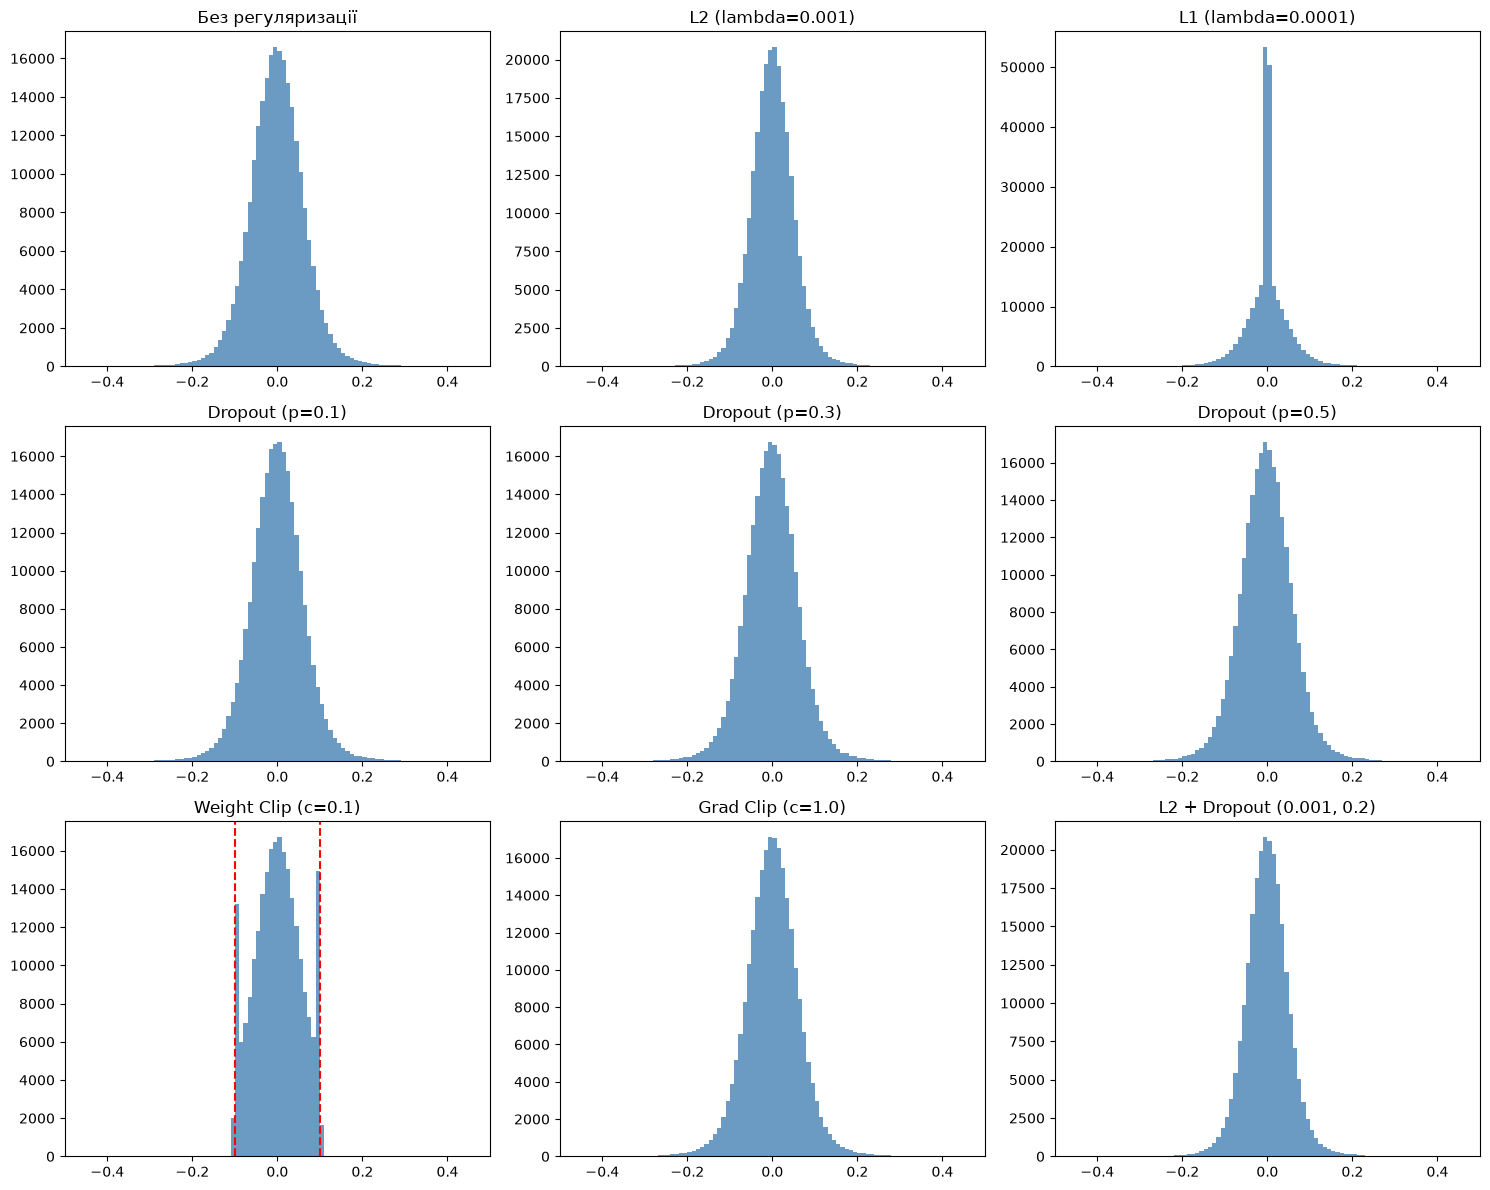

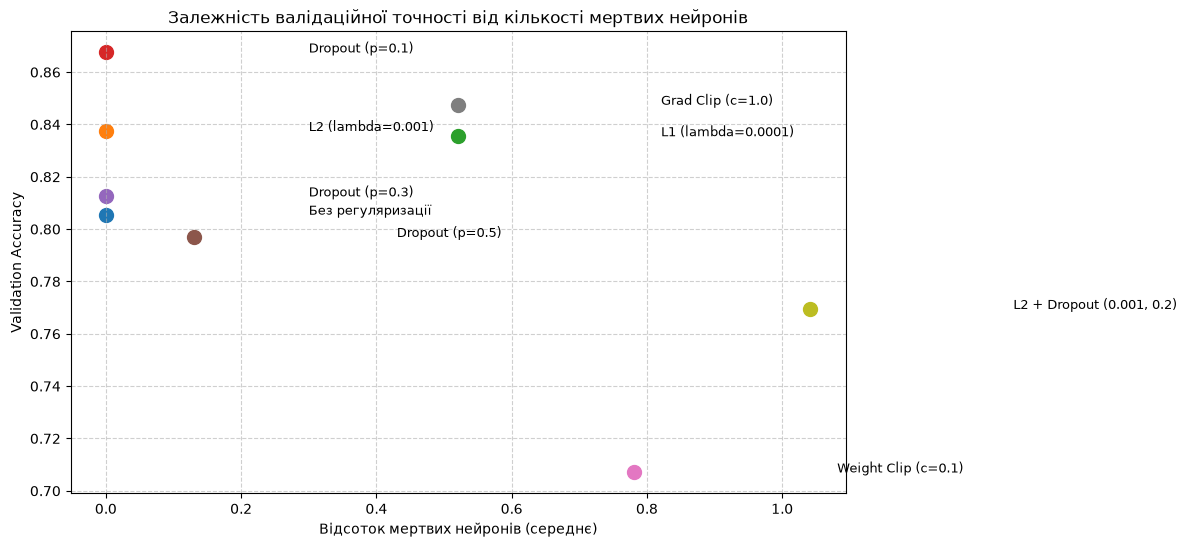

In [5]:
# 1. Порівняльна таблиця
table_data = []
for name, res in results.items():
    table_data.append({
        'Метод': name,
        'Dead neurons, %': f"{res['dead_percent']:.2f}",
        'Sparsity, %': f"{res['sparsity']:.2f}",
        'Val. accuracy': f"{res['val_acc']:.4f}",
        'Val. loss': f"{res['val_loss']:.4f}"
    })
df_results = pd.DataFrame(table_data)
print("\n--- Порівняльна таблиця результатів ---")
print(df_results.to_string())

# 2. Гістограми розподілу ваг
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(models_dict.items()):
    all_weights = np.concatenate([W.flatten() for W in model.weights])
    axes[i].hist(all_weights, bins=100, range=(-0.5, 0.5), color='steelblue', alpha=0.8)
    axes[i].set_title(name)
    axes[i].set_xlim(-0.5, 0.5)
    if 'Weight Clip' in name:
        axes[i].axvline(-0.1, color='r', linestyle='dashed')
        axes[i].axvline(0.1, color='r', linestyle='dashed')

plt.tight_layout()
plt.show()

# 3. Графік: Мертві нейрони vs Точність
plt.figure(figsize=(10, 6))
for name, res in results.items():
    plt.scatter(res['dead_percent'], res['val_acc'], s=100, label=name)
    plt.text(res['dead_percent'] + 0.3, res['val_acc'], name, fontsize=9)

plt.xlabel('Відсоток мертвих нейронів (середнє)')
plt.ylabel('Validation Accuracy')
plt.title('Залежність валідаційної точності від кількості мертвих нейронів')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

У результаті виконання лабораторної роботи було успішно реалізовано повнозв'язну нейронну мережу з нуля та досліджено механізм зворотного поширення помилки за допомогою виключно матричних операцій. Перевірка градієнтів чисельним методом повністю підтвердила коректність математичної моделі, а реалізований механізм збереження ваг у бінарному форматі довів свою ефективність для створення чекпоінтів та відновлення стану моделі. Експериментальне дослідження методів регуляризації наочно продемонструвало, що збільшення сили регуляризації не завжди є корисним: слабка або помірна регуляризація ефективно бореться з перенавчанням, тоді як надмірна (наприклад, високий рівень Dropout або жорстке обмеження ваг) обмежує гнучкість мережі та призводить до недонавчання. Аналіз різних підходів підтвердив теоретичні відомості: L1-регуляризація активно створює розріджені матриці, зводячи багато ваг до нуля, тоді як L2-регуляризація лише рівномірно зменшує їхню величину без масового занулення. Дослідження явища мертвих нейронів для функції ReLU показало, що хоча певна кількість неактивних нейронів є нормальною ознакою розрідженості активацій, їх критичне зростання суттєво обмежує пропускну здатність моделі та погіршує результати. Найкращу узагальнювальну здатність та стабільність показав комбінований підхід (L2 разом із Dropout), оскільки ці методи діють синергетично, одночасно контролюючи величину параметрів та запобігаючи коадаптації нейронів під час тренування.